In [ ]:

import os
import matplotlib.pyplot as plt
import gc
import torch
import os
import sys
sys.path.insert(0, os.path.abspath(os.path.join("..")))
from pipeline.preprocessing import BackgroundEraser
import glob

from PIL import Image
from torchvision import transforms

import pandas as pd
import re as regex_module
import numpy as np
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, fcluster

from ultralytics import YOLO

from pipeline.preprocessing import Repair, Normalizer, Augmentor
from pipeline.feature_learning.vae import VAE
from pipeline.feature_learning.vae_classifier import VAEClassifier
from pipeline.clustering import HierarchicalClustering
from pipeline.evaluation import EvaluationWithGroundTruth, EvaluationWithNoGroundTruth

# PIPELINE

## Configuration

Set `source_folder` and `run_id` here, then any section below can be run
on its own (fresh kernel included) as long as this cell has run first -
every step reads/writes under `pipeline_dir`, which is namespaced by
`run_id`, so nothing else in the notebook needs editing when you point at
new photos or start a new experiment run.

- **New photos added to `source_folder`?** Just re-run from the top with
  a new `run_id` - the old run's outputs stay untouched under their own
  `pipeline_dir`.
- **Want to jump straight to e.g. Clustering?** Run this cell, then the
  cells in that section alone - they all read their input from disk via
  the paths defined here, not from variables set by earlier sections.

In [ ]:
# --- Edit these two for a new run ------------------------------------
source_folder = "/caa/Homes01/alaczko/Diploma/Diploma/data/raw"
run_id = "run_2026-09-08"
# -----------------------------------------------------------------------

labels_path = "/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_results.csv"
test_image_path = "/caa/Homes01/alaczko/Diploma/Diploma/data/test3.png"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Every step's output lives under here, namespaced by run_id - switching
# run_id (or source_folder) is enough to start a fully separate run.
pipeline_dir = f"../data/pipeline/{run_id}"

erased_dir = f"{pipeline_dir}/erased"
normalized_dir = f"{pipeline_dir}/normalized"
repaired_dir = f"{pipeline_dir}/repaired"
augmented_dir = f"{pipeline_dir}/augmented"

# Toggle: train VAE/VAEClassifier on the augmented set, or set this to
# repaired_dir to skip augmentation and train directly on the repaired images.
feature_learning_input_dir = augmented_dir

vae_checkpoint_path = f"{pipeline_dir}/vae.pt"
vae_features_csv = f"{pipeline_dir}/vae_features.csv"
dinov3_features_csv = f"{pipeline_dir}/dinov3_features.csv"
classifier_output_dir = f"{pipeline_dir}/classifier"

# Toggle: which feature set the Clustering section below clusters on.
features_csv_for_clustering = vae_features_csv
features_scaled_csv = f"{pipeline_dir}/features_scaled.csv"

roco_labels = pd.read_csv(labels_path)

In [63]:
roco_labels["TypeRev"].unique()

array(['pan', 'lid', 'pot', 'basin', 'jug', 'bottle', 'domestic amphora', 'jar', 'bowl', 'censer', 'dish-lid', 'base', 'knob', 'mortarium', 'dish', 'beaker', 'cencer', 'unguentarium', 'pitcher', nan, 'nd', 'handle', 'cooking stand', 'mortar', 'dolium', 'funnel', 'bedpan', 'basin '], dtype=object)

## Preprocessing

### Shard selection and  background cleaning

In [ ]:
br = BackgroundEraser(
    input_path=source_folder,
    output_path=erased_dir,
    batch_size=32,
    num_workers=16,
    run_id=run_id,
)
#todo "detected 6171 shards, but erased len is 2800"
br.run()

### Resize & Crop

In [ ]:
crop_step = Normalizer(
    input_path=erased_dir,
    output_path=normalized_dir,
    background_color=(255, 255, 255),
    run_id=run_id,
)

crop_step.run()

### Enhancing Picture Quality

In [ ]:
repair_step = Repair(
    input_path=normalized_dir,
    output_path=repaired_dir,
    max_distance=20,
    output_thickness=3,
    run_id=run_id,
)

repair_step.run()

### Data Augmentation

Optional: grows the (small) labelled dataset with randomly rotated/flipped/
jittered copies before training, to fight the overfitting seen earlier when
fine-tuning `VAEClassifier` end to end. Sits right after `Repair`, before
any training step.

In [ ]:
augment_step = Augmentor(
    input_path=repaired_dir,
    output_path=augmented_dir,
    num_augmentations=2,   # 2 extra randomly perturbed copies per image
    run_id=run_id,
)

augment_step.run()

Every Feature Learning cell below reads its input from
`feature_learning_input_dir` (set in Configuration) rather than a variable
from this section - it defaults to `augmented_dir`; set it to
`repaired_dir` there instead to skip augmentation.

## Feature Learning

### VAE

In [ ]:
vae = VAE(input_path=feature_learning_input_dir, f=4, n=3, s=1, k=128, run_id=run_id)  # k=128 latent dimension
vae.to(device)

results = vae.run('train_model', epochs=1000, lr=1e-6, batch_size=128)

torch.save(vae.state_dict(), vae_checkpoint_path)

In [ ]:
vae = VAE(input_path=feature_learning_input_dir, f=4, n=3, s=1, k=128, run_id=run_id)
vae.to(device)

vae.load_state_dict(torch.load(vae_checkpoint_path, map_location=device))

results = vae.extract_features(batch_size=128)

In [5]:
results

,filename,features,sigma
0,BERT11-100b.png,"[-0.20371832, -1.6475838, 1.6958758, 1.4939508...","[-6.1585937, -6.2113166, -6.1073694, -6.150560..."
1,BERT11-101.png,"[0.3037749, -1.2438442, 0.87233955, 1.5719664,...","[-5.9918966, -6.053347, -5.759898, -6.1980515,..."
2,BERT11-102.png,"[0.18726331, -0.5456241, 0.0029010915, 1.37218...","[-6.2696257, -6.232404, -6.0650287, -6.394856,..."
3,BERT11-103.png,"[-0.45374608, 0.15573749, -0.13712779, 1.69181...","[-6.1694946, -5.827094, -5.9476433, -6.463216,..."
4,BERT11-104.png,"[-0.64298165, -1.5965886, 1.4541998, 2.5068662...","[-6.049013, -6.0839777, -6.114392, -6.06104, -..."
...,...,...,...
4615,STAN01-9.I2FF9.246.png,"[-0.76627713, 1.0280409, 0.048092667, -1.07967...","[-5.9656587, -5.731643, -4.9438186, -5.344097,..."
4616,STAN01-9.I2FF9.247.png,"[-0.31306577, 0.54145503, 0.5984157, 1.3354032...","[-6.17209, -5.628698, -5.9798203, -6.167507, -..."
4617,STAN01-9.I2FF9.248.png,"[-0.80437845, 1.9800146, 0.7083365, 0.6802149,...","[-6.359493, -6.0637603, -5.7420087, -6.1503453..."
4618,STAN01-9.I2FF9.249.png,"[0.49197742, 1.6399635, -0.16094849, 0.4550632...","[-6.572198, -6.3020177, -5.9707885, -6.364307,..."


In [ ]:
results.to_csv(vae_features_csv, index=False)

#### Testing Feature Learning

In [ ]:
vae = VAE(input_path=feature_learning_input_dir, f=4, n=3, s=1, k=128, run_id=run_id)
vae.to(device)

vae.load_state_dict(torch.load(vae_checkpoint_path, map_location=device))

#making sure the formula is correct
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

original_img = Image.open(test_image_path)
input_tensor = transform(original_img).unsqueeze(0).to(device) #adding batch dim

with torch.no_grad():
    reconstructed, mu, sigma = vae(input_tensor)

orig_np = input_tensor.squeeze().cpu().numpy()
recon_np = reconstructed.squeeze().cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(orig_np, cmap='gray', vmin=0, vmax=1)
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(recon_np, cmap='gray', vmin=0, vmax=1)
axes[1].set_title("Reconstructed")
axes[1].axis('off')

plt.tight_layout()
plt.show()

### DINOv3 (pretrained feature extractor, alternative to the VAE)

Instead of training an encoder from scratch, this uses Meta's DINOv3 - a
self-supervised Vision Transformer pretrained on ~1.7B natural images - as
a frozen feature extractor. No training happens here at all; every image
is just embedded once with the pretrained backbone.

Why try this: a VAE's encoder is only ever pushed to encode whatever makes
*pixel reconstruction* easy (see the earlier discussion on the encoder
being weak for classification) - DINO-style self-supervised training
optimizes for a much more discriminative objective, so its features tend
to transfer to downstream classification/clustering far better than plain
autoencoder features, even though DINOv3 was never shown an image of a
pottery sherd during its own training. It's a useful baseline for exactly
that reason: if DINOv3's *generic* features already separate your pottery
types better than the *purpose-built* VAE does, that's strong evidence the
VAE (or its BCE+KL training objective) - not the amount of data - is the
bottleneck.

**Before running this**: DINOv3 checkpoints are gated on Hugging Face.
Accept the license at the model page (e.g.
https://huggingface.co/facebook/dinov3-vitb16-pretrain-lvd1689m) with the
account you'll authenticate with, then run `huggingface-cli login` once
(or set the `HF_TOKEN` environment variable) before executing the next
cell - otherwise the download will fail with a 403.

In [ ]:
from transformers import AutoImageProcessor, AutoModel

# Swap for "facebook/dinov3-vits16-pretrain-lvd1689m" (smaller/faster) or
# "facebook/dinov3-vitl16-pretrain-lvd1689m" (larger/slower, likely better
# features) to compare backbone sizes.
DINOV3_MODEL_NAME = "facebook/dinov3-vitb16-pretrain-lvd1689m"

dinov3_processor = AutoImageProcessor.from_pretrained(DINOV3_MODEL_NAME)
dinov3_model = AutoModel.from_pretrained(DINOV3_MODEL_NAME).to(device)
dinov3_model.eval()  # frozen - inference only, no training/fine-tuning here

In [ ]:
from pipeline.preprocessing.dataset import collect_image_paths


@torch.no_grad()
def extract_dinov3_features(image_paths, batch_size=32):
    """Embed each image with the frozen DINOv3 backbone's CLS token - the
    standard whole-image descriptor for ViT-style models, analogous to the
    VAE's `mu`. Returns a 'filename' + 'features' row per image, i.e. the
    same shape as `VAE.extract_features`'s output, so it can be pointed at
    directly from the Clustering section below by just swapping the CSV
    path - no other changes needed there.
    """
    filenames = []
    all_features = []

    for start in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[start:start + batch_size]
        # DINOv3 (like most ImageNet-pretrained ViTs) expects 3-channel
        # RGB input; convert("RGB") turns our grayscale line drawings into
        # a 3-channel image with all channels equal.
        images = [Image.open(p).convert("RGB") for p in batch_paths]

        inputs = dinov3_processor(images=images, return_tensors="pt").to(device)
        outputs = dinov3_model(**inputs)
        cls_embeddings = outputs.last_hidden_state[:, 0, :]

        filenames.extend(p.name for p in batch_paths)
        all_features.append(cls_embeddings.cpu())

    features = torch.cat(all_features, dim=0).numpy()
    return pd.DataFrame({"filename": filenames, "features": list(features)})


dinov3_image_paths = collect_image_paths(feature_learning_input_dir)
print(f"Found {len(dinov3_image_paths)} images for DINOv3 feature extraction")

dinov3_results = extract_dinov3_features(dinov3_image_paths, batch_size=128)
dinov3_results

In [ ]:
dinov3_results.to_csv(dinov3_features_csv, index=False)

To cluster on DINOv3 features instead of the VAE's, set
`features_csv_for_clustering = dinov3_features_csv` in Configuration
instead of `vae_features_csv`. One difference to account for: DINOv3 has
no `sigma` (it's deterministic, not a VAE) - so skip the
`df['sigma'] = ...` parsing line and the mu+sigma concatenation in the
scaling cell, and just standardize `df['features']` directly (single
`mu_matrix`-equivalent, no `hstack`).

### Classifier

In [ ]:
vae = VAE(input_path=feature_learning_input_dir, f=4, n=3, s=1, k=128, run_id=run_id)
vae.to(device)

vae.load_state_dict(torch.load(vae_checkpoint_path, map_location=device))

In [ ]:
classifier = VAEClassifier(
    input_path=feature_learning_input_dir,
    vae=vae,                         # a fentebb betanított VAE
    num_classes=28,
    labels_path=labels_path,
    freeze_encoder=True,             # először csak a classifier tanul
    output_path=classifier_output_dir,
    run_id=run_id,
).to(device)

history = classifier.run(
    epochs=200,
    lr=1e-4,
    batch_size=128,
    validation_size=0.2,
    num_workers=16,
)

history

### Clustering

In [ ]:
df = pd.read_csv(features_csv_for_clustering)

In [38]:
import numpy as np
import ast

def parse_feature_string(s):
    if isinstance(s, str):
        cleaned = s.strip('[]')
        # tetszőleges mennyiségű whitespace -> egyetlen szóköz
        cleaned = regex_module.sub(r'\s+', ' ', cleaned).strip()
        return np.fromstring(cleaned, sep=' ')
    return np.asarray(s)

In [39]:
df['features'] = df['features'].apply(parse_feature_string)

In [ ]:
X = np.vstack(df['features'].values)

# 2. inaktív / szinte nulla varianciájú dimenziók kiszűrése (opcionális, de ajánlott)
variances = X.var(axis=0)
active_dims = variances > 1e-3   # threshold-öt finomítsd a saját adatodra
X_active = X[:, active_dims]

# 3. standardizálás (dimenziónkénti z-score)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_active)

df["features_non_scaled"] = df['features'] 

# 4. opcionálisan visszaírhatod a df-be, hogy egyben tudd kezelni
df['features'] = list(X_scaled)

df.to_csv(features_scaled_csv, index=False)

In [42]:
df.head()

,filename,features,features_non_scaled
0,BERT11-100b.png,"[-0.9788053422672244, 0.06230357955920411, -1....","[-0.24157, 0.65206, 0.014989, 0.73596, 0.09172..."
1,BERT11-101.png,"[-2.3375422719434673, -0.33780000109031194, 0....","[-0.67313, 0.48648, 0.40328, 1.1255, 0.076421,..."
2,BERT11-102.png,"[-1.9009493299696871, -0.049743787482214384, -...","[-0.53446, 0.60569, 0.19189, 1.3359, 0.024914,..."
3,BERT11-103.png,"[-0.6623250471262104, -0.41087121910481483, -1...","[-0.14105, 0.45624, 0.10427, 0.91697, -0.06213..."
4,BERT11-104.png,"[-0.05811278130630547, -0.28577542027509234, -...","[0.050859, 0.50801, 0.08645, 1.1814, 0.1228, -..."


In [ ]:
clustering_step = HierarchicalClustering(
    input_path=features_scaled_csv,
    cluster_num=55,
    run_id=run_id,
)
# result= clustering_step.run()


#result = clustering_step.compare_all()

In [44]:
result= clustering_step.run()

In [45]:
np.unique(result, return_counts=True)

(array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55], dtype=int32),
 array([   1,    1,    7,    4,    1,    3,    1,    1,    1,    5,    2,    1,    1,    1,    3,   20,   47,    1,    2,   11,   23,   82,    2,   11,   31,   11,    7,    9,    3,    4,   35,   47,    5,   21,    2,   16,   14,  303,   11,    7,  886,   16,  617, 2317,    2,    2,    2,    1,    1,    2,   12,    1,
           1,    1,    1]))

#### Silhouette Score (no ground truth needed)

In [46]:
# Unsupervised evaluation: uses only the feature vectors + predicted cluster
# labels, so it works even before/without matching against ground-truth types.
silhouette_step = EvaluationWithNoGroundTruth(features=clustering_step.vectors, y_pred=result)
silhouette_step.run()

Predicted labels: [41 41 41 ...  4 41 41]
Calculating silhouette score...
-----
Evaluation results: 
Silhouette Score = 0.016731161102975484
-----




In [47]:
df["pred"] = list(result)

In [48]:
df["filename"] = df["filename"].str.rsplit(".", n=1).str[0]

In [50]:
new_df = pd.merge(
    df,
    roco_labels,
    left_on="filename",
    right_on="ID",
    how="inner"
)

In [51]:
new_df = new_df.dropna(subset=["pred", "TypeRev"]).reset_index(drop=True)

In [52]:
new_df

,filename,features,features_non_scaled,pred,ID,TypeRev,source_sheet
0,BERT11-100b,"[-0.9788053422672244, 0.06230357955920411, -1....","[-0.24157, 0.65206, 0.014989, 0.73596, 0.09172...",41,BERT11-100b,pan,BERT11
1,BERT11-101,"[-2.3375422719434673, -0.33780000109031194, 0....","[-0.67313, 0.48648, 0.40328, 1.1255, 0.076421,...",41,BERT11-101,pan,BERT11
2,BERT11-102,"[-1.9009493299696871, -0.049743787482214384, -...","[-0.53446, 0.60569, 0.19189, 1.3359, 0.024914,...",41,BERT11-102,pan,BERT11
3,BERT11-103,"[-0.6623250471262104, -0.41087121910481483, -1...","[-0.14105, 0.45624, 0.10427, 0.91697, -0.06213...",41,BERT11-103,pan,BERT11
4,BERT11-104,"[-0.05811278130630547, -0.28577542027509234, -...","[0.050859, 0.50801, 0.08645, 1.1814, 0.1228, -...",41,BERT11-104,pan,BERT11
...,...,...,...,...,...,...,...
4592,STAN01-9.I2FF9.246,"[0.5268373829848219, 0.3152740099143066, -0.03...","[0.23665, 0.75675, 0.32449, 0.72846, 0.16003, ...",41,STAN01-9.I2FF9.246,lid,STAN01
4593,STAN01-9.I2FF9.247,"[-0.39131124563950787, -0.5540415123375955, -0...","[-0.054971, 0.39699, 0.30981, 0.66189, 0.00183...",38,STAN01-9.I2FF9.247,lid,STAN01
4594,STAN01-9.I2FF9.248,"[-0.06630499905358878, -2.026097928158862, 0.2...","[0.048257, -0.21221, 0.38699, 0.55541, 0.10391...",4,STAN01-9.I2FF9.248,lid,STAN01
4595,STAN01-9.I2FF9.249,"[-1.0620498608061062, -1.6384676817484611, 1.0...","[-0.26801, -0.051792, 0.53526, 1.1817, 0.05695...",41,STAN01-9.I2FF9.249,lid,STAN01


In [53]:
eval_step = EvaluationWithGroundTruth(y_true=new_df["TypeRev"].values, y_pred=new_df["pred"].values)

Ground truth labels: ['pan' 'pan' 'pan' ... 'lid' 'lid' 'dish-lid']
Predicted labels: [41 41 41 ...  4 41 41]


In [54]:
eval_step.run()

-----
Evaluation results: 
ACC = 0.29780291494452904, 
ARI = 0.06622982905136084, 
NMI = 0.17439197370224785
-----




In [ ]:
features_path = features_scaled_csv

cluster_numbers = range(3, 40)
metric_results = []

# A features.csv sorrendjében találhatók a klaszterezés bemenetei
features_df = pd.read_csv(features_path)

features_df["filename"] = (
    features_df["filename"]
    .astype(str)
    .str.strip()
    .str.rsplit(".", n=1)
    .str[0]
)

In [ ]:
for cluster_num in cluster_numbers:
    clustering_step = HierarchicalClustering(
        input_path=features_path,
        cluster_num=cluster_num,
        run_id=run_id,
    )

    predicted_labels = clustering_step.run()

    # Unsupervised metric: doesn't need the ground-truth join below, so it's
    # computed on every sample that went into clustering.
    silhouette_step = EvaluationWithNoGroundTruth(
        features=clustering_step.vectors, y_pred=predicted_labels
    )
    silhouette_step.run()

    predictions_df = features_df[["filename"]].copy()
    predictions_df["pred"] = predicted_labels

    # Az új klasztercímkék hozzárendelése a meglévő dataframe-hez
    current_df = pd.merge(
        predictions_df,
        roco_labels,
        left_on="filename",
        right_on="ID",
        how="inner"
    )

    current_df = current_df.dropna(subset=["pred", "TypeRev"]).reset_index(drop=True)

    y_true = current_df["TypeRev"].to_numpy()
    y_pred = current_df["pred"].to_numpy()


    eval_step = EvaluationWithGroundTruth(y_true=y_true, y_pred=y_pred)

    eval_step.run()

    metric_results.append({
        "cluster_num": cluster_num,
        "ACC": eval_step.acc,
        "ARI": eval_step.ari,
        "NMI": eval_step.nmi,
        "Silhouette": silhouette_step.silhouette,
        "sample_count": len(current_df),
        "predicted_cluster_count": current_df["pred"].nunique(),
    })

metrics_df = pd.DataFrame(metric_results)
metrics_df

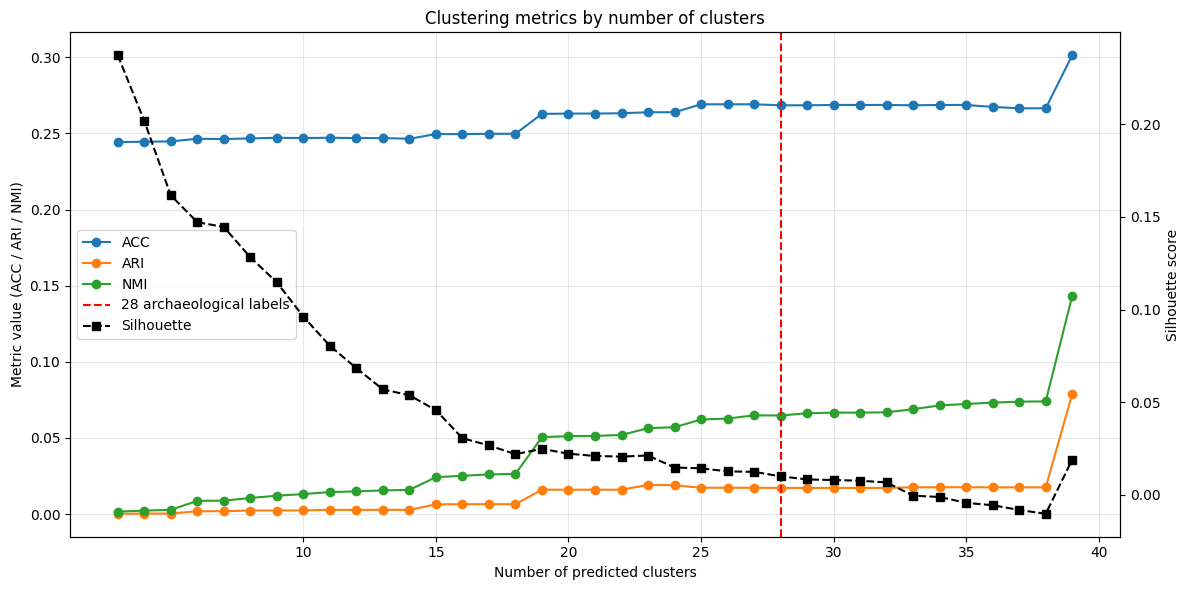

In [60]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(
    metrics_df["cluster_num"],
    metrics_df["ACC"],
    marker="o",
    label="ACC"
)

ax1.plot(
    metrics_df["cluster_num"],
    metrics_df["ARI"],
    marker="o",
    label="ARI"
)

ax1.plot(
    metrics_df["cluster_num"],
    metrics_df["NMI"],
    marker="o",
    label="NMI"
)

ax1.axvline(
    28,
    color="red",
    linestyle="--",
    label="28 archaeological labels"
)

ax1.set_xlabel("Number of predicted clusters")
ax1.set_ylabel("Metric value (ACC / ARI / NMI)")
ax1.set_xticks(range(10, 61, 5))
ax1.grid(alpha=0.3)

# Silhouette score has a different range ([-1, 1], unsupervised - no ground
# truth involved) than ACC/ARI/NMI, so it gets its own y-axis rather than
# being squashed onto the same 0-1 scale.
ax2 = ax1.twinx()
ax2.plot(
    metrics_df["cluster_num"],
    metrics_df["Silhouette"],
    marker="s",
    color="black",
    linestyle="--",
    label="Silhouette",
)
ax2.set_ylabel("Silhouette score")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.title("Clustering metrics by number of clusters")
plt.tight_layout()
plt.show()

In [58]:
new_df

,filename,features,features_non_scaled,pred,ID,TypeRev,source_sheet
0,BERT11-100b,"[-0.9788053422672244, 0.06230357955920411, -1....","[-0.24157, 0.65206, 0.014989, 0.73596, 0.09172...",41,BERT11-100b,pan,BERT11
1,BERT11-101,"[-2.3375422719434673, -0.33780000109031194, 0....","[-0.67313, 0.48648, 0.40328, 1.1255, 0.076421,...",41,BERT11-101,pan,BERT11
2,BERT11-102,"[-1.9009493299696871, -0.049743787482214384, -...","[-0.53446, 0.60569, 0.19189, 1.3359, 0.024914,...",41,BERT11-102,pan,BERT11
3,BERT11-103,"[-0.6623250471262104, -0.41087121910481483, -1...","[-0.14105, 0.45624, 0.10427, 0.91697, -0.06213...",41,BERT11-103,pan,BERT11
4,BERT11-104,"[-0.05811278130630547, -0.28577542027509234, -...","[0.050859, 0.50801, 0.08645, 1.1814, 0.1228, -...",41,BERT11-104,pan,BERT11
...,...,...,...,...,...,...,...
4592,STAN01-9.I2FF9.246,"[0.5268373829848219, 0.3152740099143066, -0.03...","[0.23665, 0.75675, 0.32449, 0.72846, 0.16003, ...",41,STAN01-9.I2FF9.246,lid,STAN01
4593,STAN01-9.I2FF9.247,"[-0.39131124563950787, -0.5540415123375955, -0...","[-0.054971, 0.39699, 0.30981, 0.66189, 0.00183...",38,STAN01-9.I2FF9.247,lid,STAN01
4594,STAN01-9.I2FF9.248,"[-0.06630499905358878, -2.026097928158862, 0.2...","[0.048257, -0.21221, 0.38699, 0.55541, 0.10391...",4,STAN01-9.I2FF9.248,lid,STAN01
4595,STAN01-9.I2FF9.249,"[-1.0620498608061062, -1.6384676817484611, 1.0...","[-0.26801, -0.051792, 0.53526, 1.1817, 0.05695...",41,STAN01-9.I2FF9.249,lid,STAN01


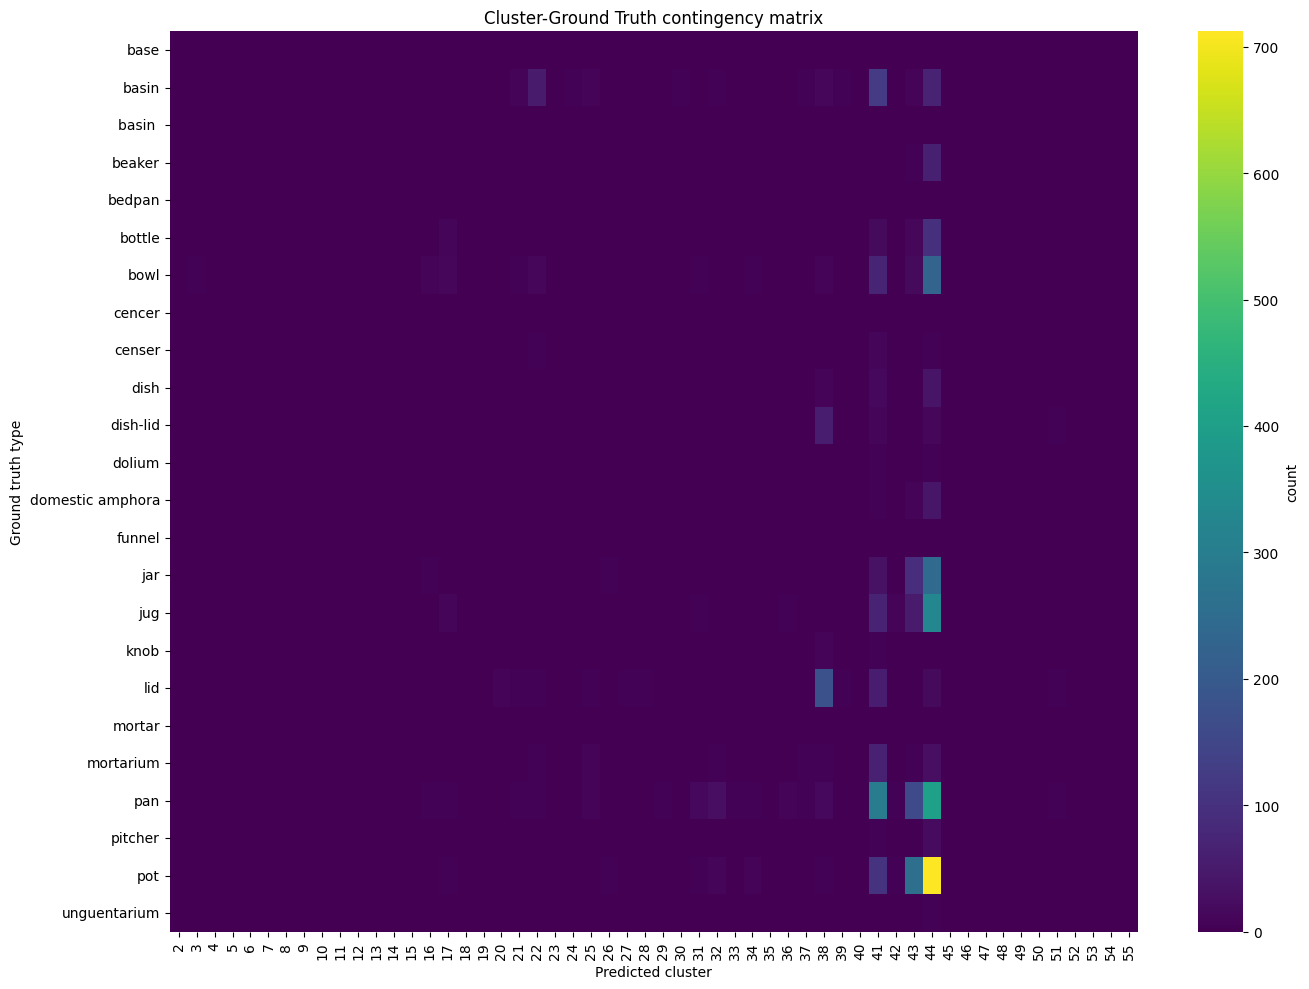

In [59]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# df-ben legyen egy 'pred' (predikált cluster) és egy 'true_label' (ground truth) oszlop
contingency = pd.crosstab(new_df['TypeRev'], new_df['pred'])

plt.figure(figsize=(14, 10))
sns.heatmap(contingency, annot=False, cmap='viridis', cbar_kws={'label': 'count'})
plt.xlabel('Predicted cluster')
plt.ylabel('Ground truth type')
plt.title('Cluster-Ground Truth contingency matrix')
plt.tight_layout()
plt.show()